## Graph Fundamentals

Plain-English Definition

A **graph** is a mathematical structure used to model **relationships between things**.

- The **things** are called **nodes** (also called *vertices*).
- The **relationships** between things are called **edges** (also called *links* or *connections*).

That's it. A graph is just: **a set of things + a set of relationships between those things.**

### Everyday Analogies

| Real-world situation | Nodes (things) | Edges (relationships) |
|----------------------|----------------|----------------------|
| Facebook friend network | People | Friendships |
| City road map | Intersections | Roads |
| Internet | Webpages | Hyperlinks |
| Airline routes | Airports | Flight routes |
| Organizational chart | Employees | Reports-to relationships |
| Recipe | Ingredients | "goes well with" |

Notice that graphs appear **everywhere**. Any time you have objects and connections between them, you have a graph.

### Why Are Graphs Useful?

Graphs let us answer powerful questions:

- **Shortest path:** What is the fastest route from city A to city B?
- **Influence:** Who is the most influential person in this social network?
- **Communities:** Which groups of people tend to interact mainly with each other?
- **Vulnerabilities:** Which road, if closed, would cause the biggest traffic disruption?
- **Recommendations:** What product should we suggest to this user based on buying patterns?

None of these questions can be easily answered with a simple table or spreadsheet. Graphs give us the tools.


## Create a Graph

In [1]:
import networkx as nx
G = nx.Graph()


G.add_nodes_from(["Alice", "Bob", "Carol", "David", "Eve"])

G.add_edges_from([
    ("Alice", "Bob"),    # Alice and Bob are friends
    ("Bob",   "Carol"),  # Bob and Carol are friends
    ("Alice", "David"),  # Alice and David are friends
    ("Carol", "Eve"),    # Carol and Eve are friends
    ("David", "Eve"),    # David and Eve are friends
])

print("=" * 50)
print("BASIC GRAPH FACTS")
print("=" * 50)

print(f"Number of nodes : {G.number_of_nodes()}")


print(f"Number of edges : {G.number_of_edges()}")


print(f"\nAll nodes       : {list(G.nodes())}")


print(f"All edges       : {list(G.edges())}")


BASIC GRAPH FACTS
Number of nodes : 5
Number of edges : 5

All nodes       : ['Alice', 'Bob', 'Carol', 'David', 'Eve']
All edges       : [('Alice', 'Bob'), ('Alice', 'David'), ('Bob', 'Carol'), ('Carol', 'Eve'), ('David', 'Eve')]


## Querying Neighbors and Degree

### What is Degree?

The **degree** of a node is the **number of edges connected to it** — in other words, the number of direct neighbors.

- In our friendship graph, if Alice is friends with Bob and David, Alice's degree is **2**.
- Degree tells you how many direct connections a node has. It does **not** tell you how important the node is (we will cover importance later).

**Mathematical notation:** degree of node v is written as `deg(v)`.

In [3]:

print("=" * 50)
print("NEIGHBORS")
print("=" * 50)

alice_neighbors = list(G.neighbors("Alice"))
print(f"Alice's neighbors : {alice_neighbors}")


bob_neighbors = list(G.neighbors("Bob"))
print(f"Bob's neighbors   : {bob_neighbors}")
# → Bob is friends with Alice and Carol.


print("\n" + "=" * 50)
print("DEGREE OF EACH NODE")
print("=" * 50)


print(f"Degree of Alice : {G.degree('Alice')}")


print("\nDegree of every node:")
for node, degree in G.degree():
    print(f"  {node:8s}  →  degree {degree}")


print("\n" + "=" * 50)
print("SUMMARY STATISTICS")
print("=" * 50)

degrees = [deg for _, deg in G.degree()]  # collect all degree values

print(f"Minimum degree  : {min(degrees)}")
print(f"Maximum degree  : {max(degrees)}")
print(f"Average degree  : {sum(degrees) / len(degrees):.2f}")


NEIGHBORS
Alice's neighbors : ['Bob', 'David']
Bob's neighbors   : ['Alice', 'Carol']

DEGREE OF EACH NODE
Degree of Alice : 2

Degree of every node:
  Alice     →  degree 2
  Bob       →  degree 2
  Carol     →  degree 2
  David     →  degree 2
  Eve       →  degree 2

SUMMARY STATISTICS
Minimum degree  : 2
Maximum degree  : 2
Average degree  : 2.00


### Output Walkthrough & Interpretation

Let's verify the degree of each node manually against the graph:

```
Alice ── Bob ── Carol
  |              |
David ─────── Eve
```

| Node | Edges to | Degree | Interpretation |
|------|----------|--------|----------------|
| Alice | Bob, David | **2** | Connected to 2 people |
| Bob | Alice, Carol | **2** | Connected to 2 people |
| Carol | Bob, Eve | **2** | Connected to 2 people |
| David | Alice, Eve | **2** | Connected to 2 people |
| Eve | Carol, David | **2** | Connected to 2 people |

Every node has degree **2** — this is a **cycle graph** (a ring). Each person has exactly two friends.

**Average degree = 2.00**. There is a universal mathematical truth:

> **Average degree = (2 × number of edges) / number of nodes**
>
> In our case: (2 × 5) / 5 = **2.00** ✓
>
> Why multiply by 2? Because each edge is *shared* by two nodes — it contributes 1 to the degree of each endpoint.

**⚠️ Degree ≠ Importance.** All five people have the same degree here, but in a real network someone with degree 2 might bridge two completely separate communities, making them far more important than their degree suggests. We will explore this in Module 2 (Betweenness Centrality).

## Visualizing the Graph

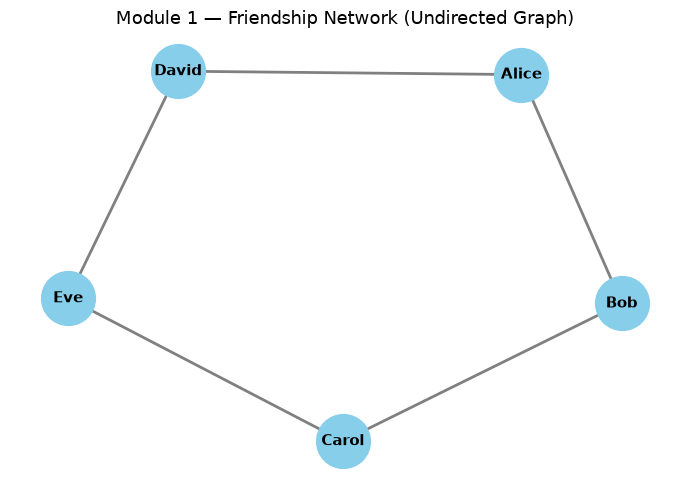

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))  # set the canvas size in inches (width x height)

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos=pos,
    with_labels=True,        # show node names
    node_color="skyblue",    # colour of the circles
    node_size=1500,          # size of the circles (in points²)
    font_size=11,            # font size of the labels
    font_weight="bold",      # make labels bold for readability
    edge_color="gray",       # colour of the lines
    width=2,                 # thickness of the lines
)

plt.title("Module 1 — Friendship Network (Undirected Graph)", fontsize=13)
plt.axis("off")   # hide the x/y axes — they are meaningless for a graph layout
plt.tight_layout()
plt.show()

## Dirtected Graphs

We will now model a **Twitter-style follow network** where following is one-directional.

```
Alice ──▶ Bob ──▶ Carol
  ▲         ▲
David       Eve ──▶ Alice
```

Follows:
- Alice follows Bob
- Bob follows Carol
- David follows Alice
- Eve follows Bob
- Eve follows Alice

In [5]:

DG = nx.DiGraph()

DG.add_nodes_from(["Alice", "Bob", "Carol", "David", "Eve"])

DG.add_edges_from([
    ("Alice", "Bob"),   # Alice follows Bob
    ("Bob",   "Carol"), # Bob follows Carol
    ("David", "Alice"), # David follows Alice
    ("Eve",   "Bob"),   # Eve follows Bob
    ("Eve",   "Alice"), # Eve follows Alice
])


print("=" * 55)
print("DIRECTED GRAPH — IN-DEGREE AND OUT-DEGREE")
print("=" * 55)
print(f"{'Node':10s}  {'In-degree (followers)':22s}  {'Out-degree (following)':22s}")
print("-" * 60)

for node in sorted(DG.nodes()):
    in_deg  = DG.in_degree(node)   # how many people follow this node
    out_deg = DG.out_degree(node)  # how many people this node follows
    print(f"{node:10s}  {in_deg:22d}  {out_deg:22d}")

print("\n")
print("Interpretation:")
print("  Bob has in-degree 2 (Alice and Eve follow him) → he is popular.")
print("  Carol has in-degree 1 (only Bob follows her).")
print("  David and Carol have out-degree 0 — they don't follow anyone in this network.")

DIRECTED GRAPH — IN-DEGREE AND OUT-DEGREE
Node        In-degree (followers)   Out-degree (following)
------------------------------------------------------------
Alice                            2                       1
Bob                              2                       1
Carol                            1                       0
David                            0                       1
Eve                              0                       2


Interpretation:
  Bob has in-degree 2 (Alice and Eve follow him) → he is popular.
  Carol has in-degree 1 (only Bob follows her).
  David and Carol have out-degree 0 — they don't follow anyone in this network.


### Visualization

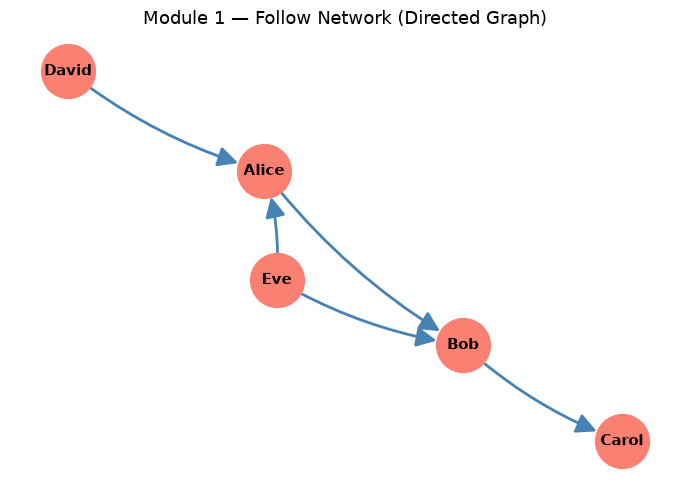

In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZE the directed graph with arrows
# ─────────────────────────────────────────────────────────────────────────────
plt.figure(figsize=(7, 5))

pos = nx.spring_layout(DG, seed=7)

# Draw nodes
nx.draw_networkx_nodes(DG, pos, node_color="salmon", node_size=1500)
nx.draw_networkx_labels(DG, pos, font_size=11, font_weight="bold")

# Draw edges with arrows.
# connectionstyle='arc3,rad=0.1' adds a slight curve so overlapping edges
# (if any) are distinguishable.
nx.draw_networkx_edges(
    DG, pos,
    edge_color="steelblue",
    node_size=1500, 
    arrows=True,
    arrowsize=30,
    width=2,
    connectionstyle="arc3,rad=0.1",
)

plt.title("Module 1 — Follow Network (Directed Graph)", fontsize=13)
plt.axis("off")
plt.tight_layout()
plt.show()

## Weighted Graphs

We will model a **city road network** where edges have distances (in km).

```
A ──(4 km)── B ──(2 km)── C
|                         |
(6 km)              (3 km)
|                         |
D ──────────(5 km)──────── E
```

In [7]:

WG = nx.Graph()

WG.add_weighted_edges_from([
    ("A", "B", 4),  # road from A to B is 4 km
    ("B", "C", 2),  # road from B to C is 2 km
    ("A", "D", 6),  # road from A to D is 6 km
    ("C", "E", 3),  # road from C to E is 3 km
    ("D", "E", 5),  # road from D to E is 5 km
])


print("=" * 50)
print("WEIGHTED GRAPH — EDGE DETAILS")
print("=" * 50)

for node_a, node_b, attributes in WG.edges(data=True):
    weight = attributes["weight"]  # retrieve the 'weight' key from the dict
    print(f"  {node_a} ──({weight} km)── {node_b}")

# ─────────────────────────────────────────────────────────────────────────────
# Access the weight of a specific edge
# ─────────────────────────────────────────────────────────────────────────────
weight_AB = WG["A"]["B"]["weight"]
print(f"\nDirect lookup: Distance from A to B = {weight_AB} km")

WEIGHTED GRAPH — EDGE DETAILS
  A ──(4 km)── B
  A ──(6 km)── D
  B ──(2 km)── C
  C ──(3 km)── E
  D ──(5 km)── E

Direct lookup: Distance from A to B = 4 km


### Visualization:

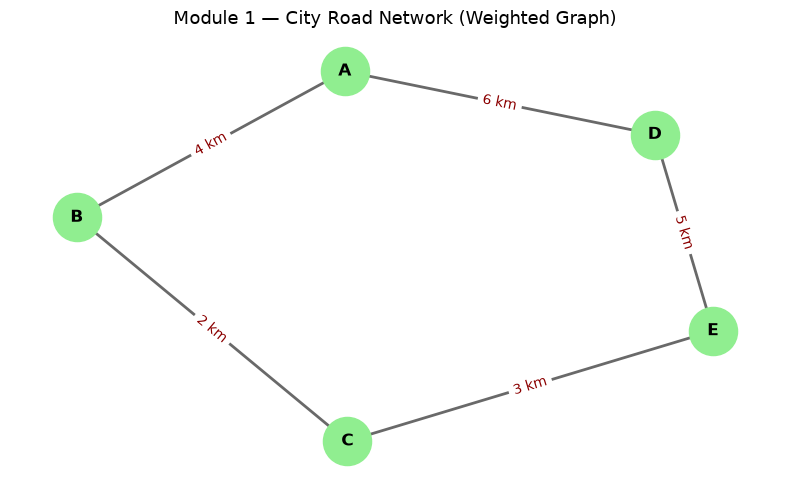

In [8]:
# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZE the weighted graph with edge labels showing distances
# ─────────────────────────────────────────────────────────────────────────────
plt.figure(figsize=(8, 5))

pos = nx.spring_layout(WG, seed=1)

# Build a dictionary {(node_a, node_b): weight_label} for edge labels
edge_labels = {(u, v): f"{d['weight']} km" for u, v, d in WG.edges(data=True)}

nx.draw_networkx(
    WG, pos,
    with_labels=True,
    node_color="lightgreen",
    node_size=1200,
    font_size=12,
    font_weight="bold",
    edge_color="dimgray",
    width=2,
)

# Draw edge weight labels
nx.draw_networkx_edge_labels(
    WG, pos,
    edge_labels=edge_labels,
    font_size=10,
    font_color="darkred",
)

plt.title("Module 1 — City Road Network (Weighted Graph)", fontsize=13)
plt.axis("off")
plt.tight_layout()
plt.show()

## Mumtigraphs and Self-loops

In [9]:

MG = nx.MultiGraph()

# Both edges connect the same pair (London, Paris) but represent different routes
MG.add_edge("London", "Paris", mode="train",  duration=2.5)  # Eurostar ~2.5h
MG.add_edge("London", "Paris", mode="flight", duration=1.2)  # flight ~1.2h
MG.add_edge("Paris",  "Berlin", mode="train", duration=8.0)

print("=" * 50)
print("MULTIGRAPH — MULTIPLE EDGES BETWEEN SAME NODES")
print("=" * 50)
print(f"Number of edges: {MG.number_of_edges()}")
# → 3, because we have 2 London–Paris edges + 1 Paris–Berlin edge

print("\nAll edges (with attributes):")
for u, v, key, data in MG.edges(data=True, keys=True):
    # 'key' is the edge index (0, 1, 2...) distinguishing multiple edges
    print(f"  {u} ──[key={key}]──▶ {v}  |  {data}")

# ─────────────────────────────────────────────────────────────────────────────
# SELF-LOOP — a node connected to itself
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 50)
print("SELF-LOOP EXAMPLE")
print("=" * 50)

SL = nx.Graph()
SL.add_nodes_from(["A", "B", "C"])
SL.add_edges_from([("A", "B"), ("B", "C"), ("C", "C")])  # C has a self-loop

print(f"Self-loops in the graph: {list(nx.selfloop_edges(SL))}")
# → [(C, C)] — C points to itself

print(f"Number of self-loops    : {nx.number_of_selfloops(SL)}")

MULTIGRAPH — MULTIPLE EDGES BETWEEN SAME NODES
Number of edges: 3

All edges (with attributes):
  London ──[key=0]──▶ Paris  |  {'mode': 'train', 'duration': 2.5}
  London ──[key=1]──▶ Paris  |  {'mode': 'flight', 'duration': 1.2}
  Paris ──[key=0]──▶ Berlin  |  {'mode': 'train', 'duration': 8.0}

SELF-LOOP EXAMPLE
Self-loops in the graph: [('C', 'C')]
Number of self-loops    : 1
